# Sobia Pervaiz
# Telecom Churn Analysis Prediction-- Comparison of Python Wrokflow and Azure Computation
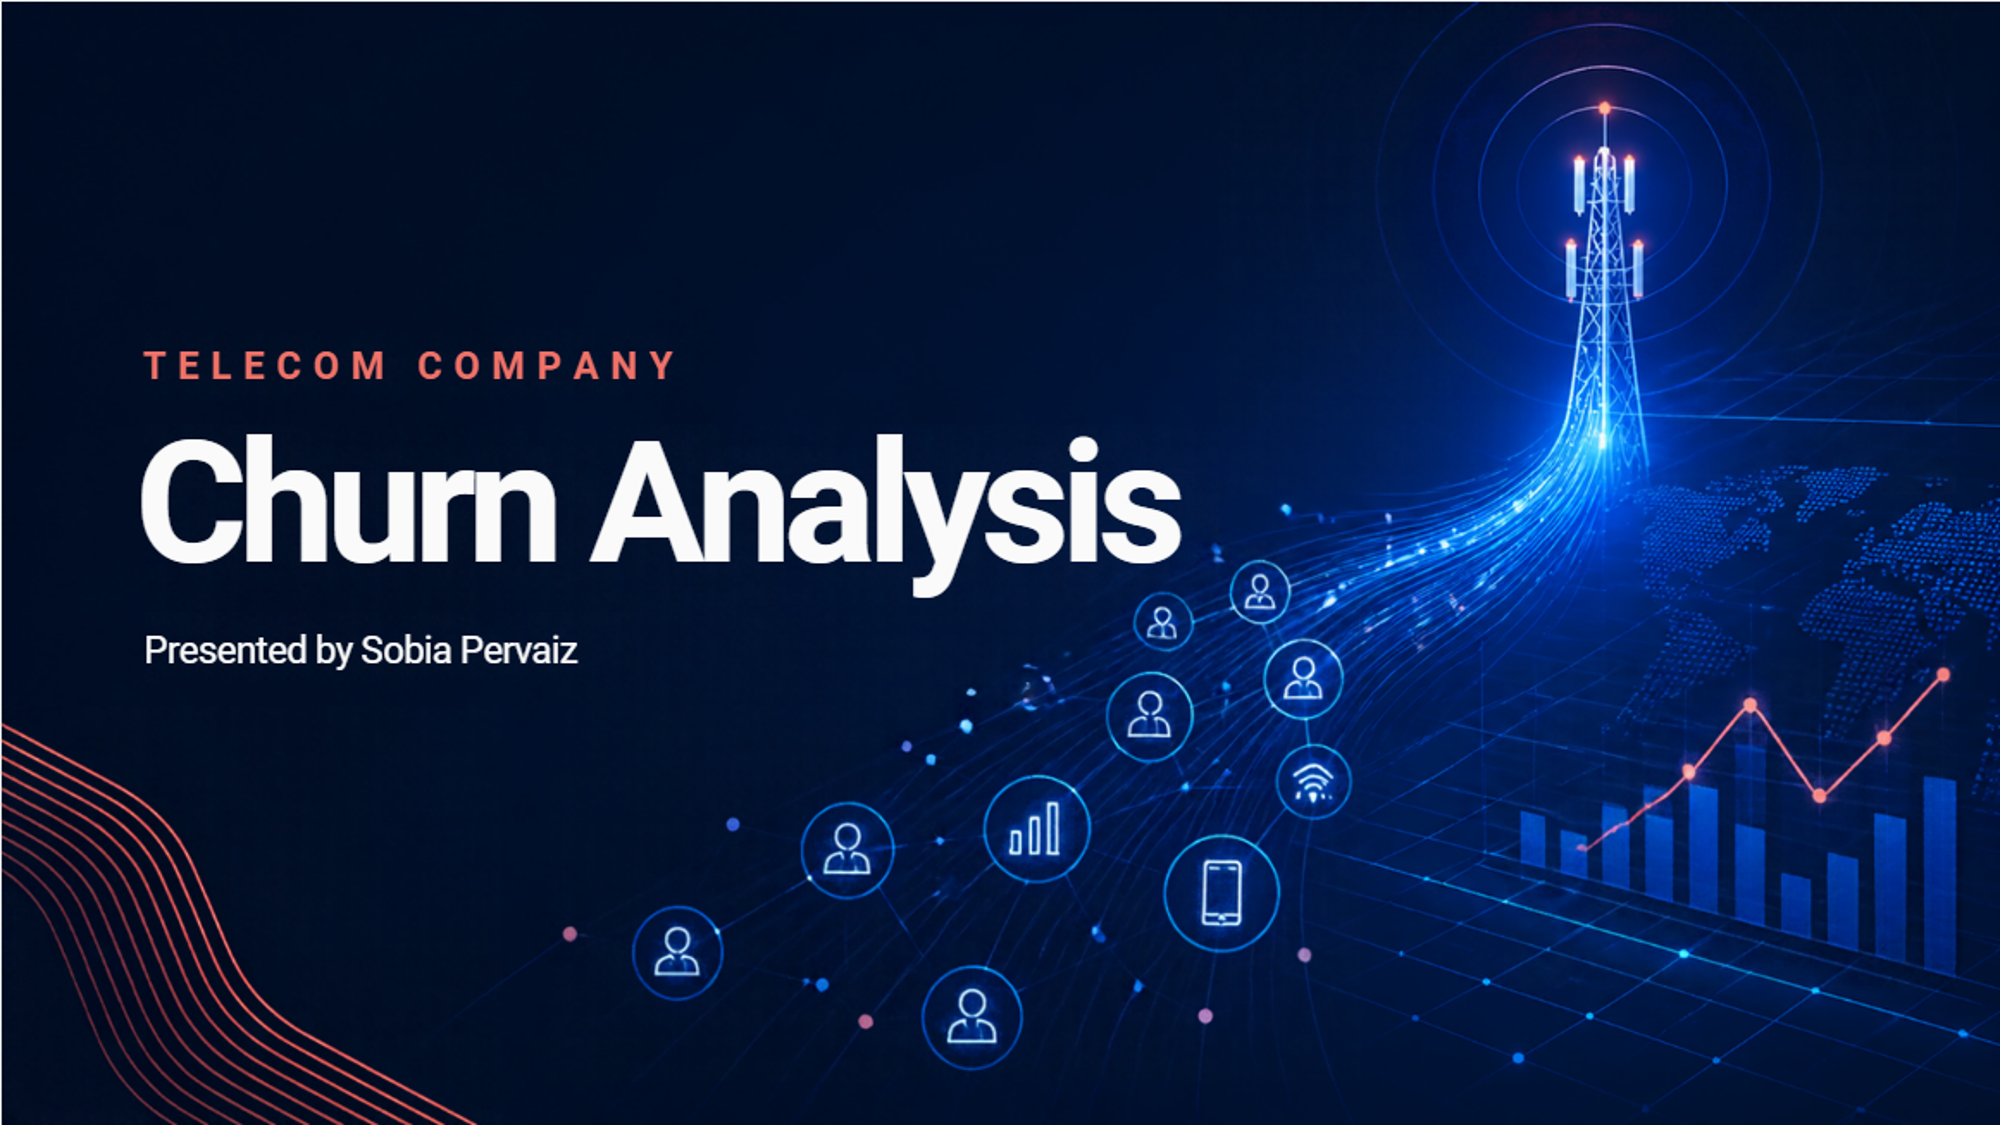

## *********************** ***Important**********************
This notebook will create a comparison of Python Coding and Azure computation results. all the parameters are chosen to be almost the same for both Azure and coding to make a real-time comparison of both the platforms. Whatever step is conducted in Python, a screenshot will show the same step performed in Azure.

## Business Objective


Telco company provided home phone and Internet services to 7043 customers in California. 
- Target is to predict the customer churn based on the relative features for the business to craft their marketing strategies accordingly to minimize the churn and enhance customer satisfaction.

## Import the dataset

### Import libraries

In [32]:
import warnings
warnings.filterwarnings('ignore')

In [150]:
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import category_encoders as ce

from sklearn.preprocessing import OneHotEncoder,MinMaxScaler

from sklearn.ensemble import RandomForestClassifier

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix,\
            classification_report,ConfusionMatrixDisplay

In [221]:
while True:
    user_input=input("Please enter the path of csv file: ").strip("'\"")
    file_path=Path(user_input)

    try:
        if not file_path.is_file():
            raise FileNotFoundError(f"No file found at: {file_path.absolute()}") # absolute()-exact path

        if file_path.suffix.lower() != ".csv":  # if wrong extension file uploaded
            raise ValueError(f"Wrong file type! Expected .xlsx, found {file_path.suffix.lower()}")

        # if no error found, read the data
        churn=pd.read_csv(file_path)
        print("File loaded successfully")
        print("Shape of dataset: ", churn.shape)

        break

    except FileNotFoundError as e:
        print(f"error: {e}")

    except ValueError as e:
        print(f"error: {e}")

    except pd.errors.EmptyDataError:
        print("Error: This file is completely empty")

    except pd.errors.ParseError:
        print("This file is corrupted or formatted incorrectly.")

    except Exception as e: # any other error
        print(f"An unexpected error occured: {e}")


Please enter the path of excel file:  "C:\Users\Owner\Downloads\Data Science Metro\Cloud Computing & Big Data\Project\Telco_customer_churn_azure.csv"


File loaded successfully
Shape of dataset:  (7043, 33)



#### Path for Telco_customer_churn.csv
"C:\Users\Owner\Downloads\Data Science Metro\Cloud Computing & Big Data\Project\Telco_customer_churn_azure.csv"

#### Kaggle link for dataset
https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset


## Azure: Data Import
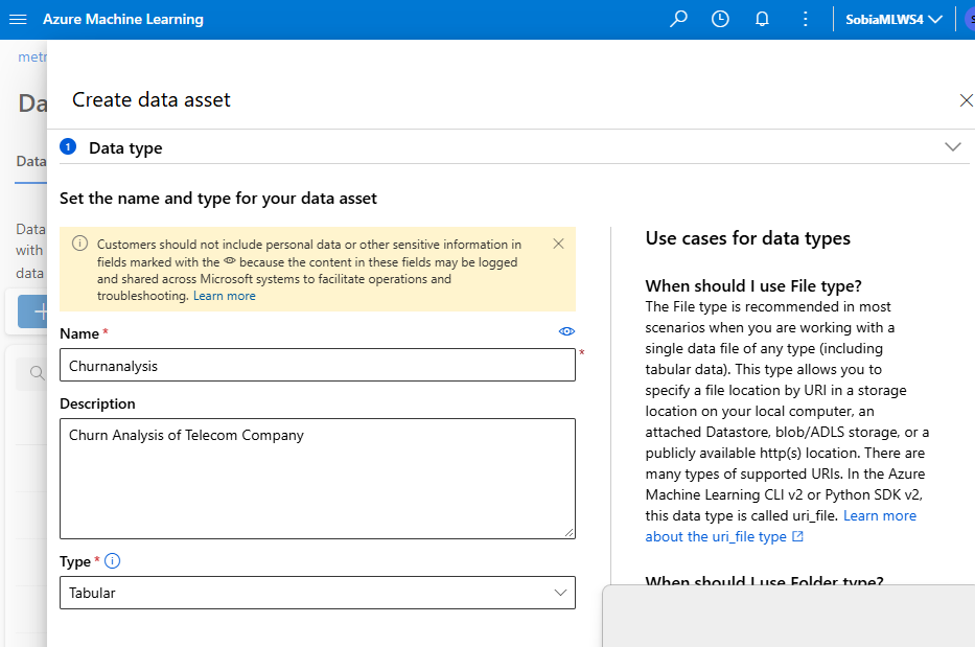

## Understanding the columns and target variable

In [222]:
pd.options.display.max_columns=500
churn.head() # first 5 records

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [223]:
churn.tail() # last 5 records

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,No,No,No,72,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,3186-AJIEK,1,United States,California,Apple Valley,92308,"34.424926, -117.184503",34.424926,-117.184503,Male,No,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No,0,38,5097,NaN


## Azure Dataset
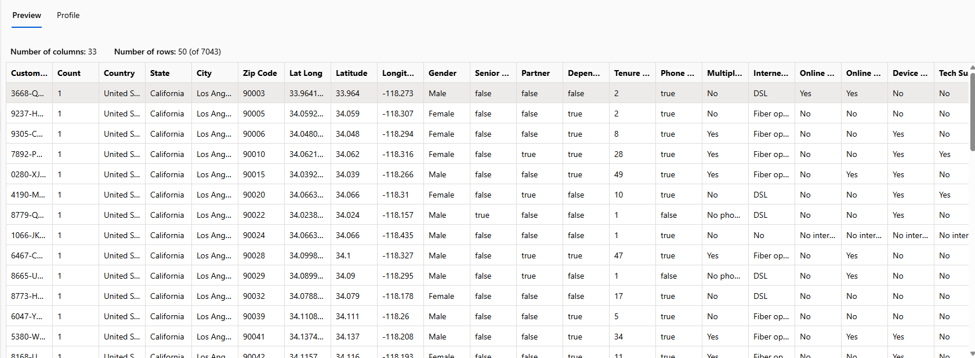

## Column Names

In [37]:
churn.columns 

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

## Shape of Dataset: rows, columns

In [38]:
churn.shape

(7043, 33)

## Check Levels of Variables
- Below is the display of number of levels for each variable in the dataset, alongwith datatype of each column.
- The following columns have fewer levels so can be considered as categorical columns:
-  - male, education, currentSmoker, BPMeds, prevalentStroke, prevalentHyp, diabetes, TenYearCHD

In [39]:
for i in range(len(churn.columns)):
    print("*"*50)
    print("-"*10, churn.columns[i], ",levels: ", churn.iloc[:,i].nunique(), ", Column dtype: ", churn[churn.columns[i]].dtypes, "-"*10)
    print(churn.iloc[:, i].value_counts())
    print()

**************************************************
---------- CustomerID ,levels:  7043 , Column dtype:  object ----------
CustomerID
3668-QPYBK    1
9237-HQITU    1
9305-CDSKC    1
7892-POOKP    1
0280-XJGEX    1
             ..
2569-WGERO    1
6840-RESVB    1
2234-XADUH    1
4801-JZAZL    1
3186-AJIEK    1
Name: count, Length: 7043, dtype: int64

**************************************************
---------- Count ,levels:  1 , Column dtype:  int64 ----------
Count
1    7043
Name: count, dtype: int64

**************************************************
---------- Country ,levels:  1 , Column dtype:  object ----------
Country
United States    7043
Name: count, dtype: int64

**************************************************
---------- State ,levels:  1 , Column dtype:  object ----------
State
California    7043
Name: count, dtype: int64

**************************************************
---------- City ,levels:  1129 , Column dtype:  object ----------
City
Los Angeles      305
San Dieg

#### Fix datatypes of 'Total Charges':
- datatype of 'Total Charges' is object
- It has 6531 levels, so it should be 'int64' type

In [40]:
churn['Total Charges'].value_counts().index

Index([    ' ',    20.2,   19.75,    19.9,   20.05,   19.65,   19.55,    45.3,
         20.15,   19.45,
       ...
         39.25,  3316.1, 2625.25,  1495.1,   743.3,  1419.4,  1990.5,  7362.9,
        346.45,   820.5],
      dtype='object', name='Total Charges', length=6531)

#### Point to Note:
- index of 'Total Charges' has a value ' ', that is causing its datatype to be object
- Step 1: replace ' ' with NaN
- Step 2: replcae NaN with 0 

In [41]:
churn['Total Charges'].dtypes # datatype of 'Total Charges'

dtype('O')

### Step 1: replace ' ' with NaN

In [42]:
churn['Total Charges'].replace(' ',np.nan, inplace=True)
churn['Total Charges'].value_counts().index

Index([   20.2,   19.75,    19.9,   20.05,   19.65,   19.55,    45.3,   19.45,
         20.15,   20.25,
       ...
         39.25,  3316.1, 2625.25,  1495.1,   743.3,  1419.4,  1990.5,  7362.9,
        346.45,  6844.5],
      dtype='float64', name='Total Charges', length=6530)

In [43]:
churn['Total Charges'].dtypes

dtype('float64')

In [44]:
# Check if '' is replaced with nan or not
null_values=churn['Total Charges'][churn['Total Charges'].isnull()==True].values
null_values

array([nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan])

## Display null value rows in dataframe
- These are the customers who are new to the company so they do not have any Total Charges. 
- Replace these Null values with zero.
- Median is not a good choice here as it will create high totoal charges for these customers which is not true.

In [45]:
churn[churn['Total Charges'].isnull()] # display null value rows in dataframe

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
2234,4472-LVYGI,1,United States,California,San Bernardino,92408,"34.084909, -117.258107",34.084909,-117.258107,Female,No,Yes,No,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No,0,36,2578,NaN
2438,3115-CZMZD,1,United States,California,Independence,93526,"36.869584, -118.189241",36.869584,-118.189241,Male,No,No,No,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No,0,68,5504,NaN
2568,5709-LVOEQ,1,United States,California,San Mateo,94401,"37.590421, -122.306467",37.590421,-122.306467,Female,No,Yes,No,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No,0,45,2048,NaN
2667,4367-NUYAO,1,United States,California,Cupertino,95014,"37.306612, -122.080621",37.306612,-122.080621,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No,0,48,4950,NaN
2856,1371-DWPAZ,1,United States,California,Redcrest,95569,"40.363446, -123.835041",40.363446,-123.835041,Female,No,Yes,No,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No,0,30,4740,NaN
4331,7644-OMVMY,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No,0,53,2019,NaN
4687,3213-VVOLG,1,United States,California,Sun City,92585,"33.739412, -117.173334",33.739412,-117.173334,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No,0,49,2299,NaN
5104,2520-SGTTA,1,United States,California,Ben Lomond,95005,"37.078873, -122.090386",37.078873,-122.090386,Female,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No,0,27,3763,NaN
5719,2923-ARZLG,1,United States,California,La Verne,91750,"34.144703, -117.770299",34.144703,-117.770299,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No,0,69,4890,NaN
6772,4075-WKNIU,1,United States,California,Bell,90201,"33.970343, -118.171368",33.970343,-118.171368,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No,0,44,2342,NaN


In [46]:
# Step 2: replcae NaN with mean of the columns
churn['Total Charges'].fillna(0, inplace=True)
churn['Total Charges'].value_counts().index

Index([    0.0,    20.2,   19.75,    19.9,   20.05,   19.65,   19.55,    45.3,
         20.15,   19.45,
       ...
         39.25,  3316.1, 2625.25,  1495.1,   743.3,  1419.4,  1990.5,  7362.9,
        346.45,   820.5],
      dtype='float64', name='Total Charges', length=6531)

## Azure: fix Datatype of 'Total Charges' and fill with 0
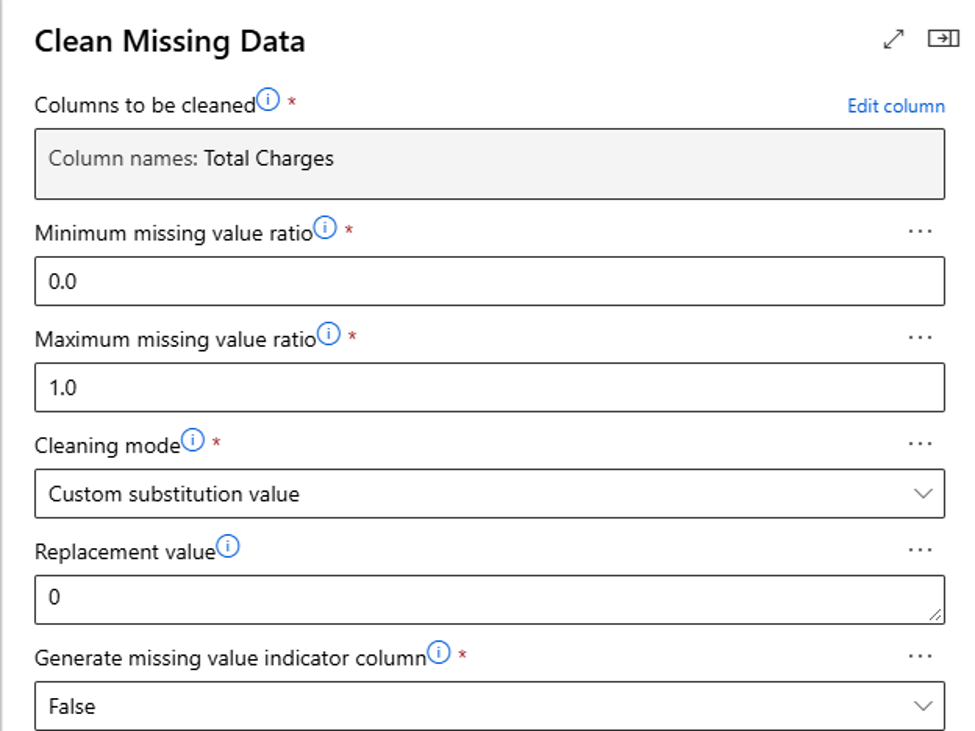

## Now Datatype is changed to 'float'

In [47]:
churn['Total Charges'].dtypes

dtype('float64')

## Azure: Change of Datatype 'Total Charges'
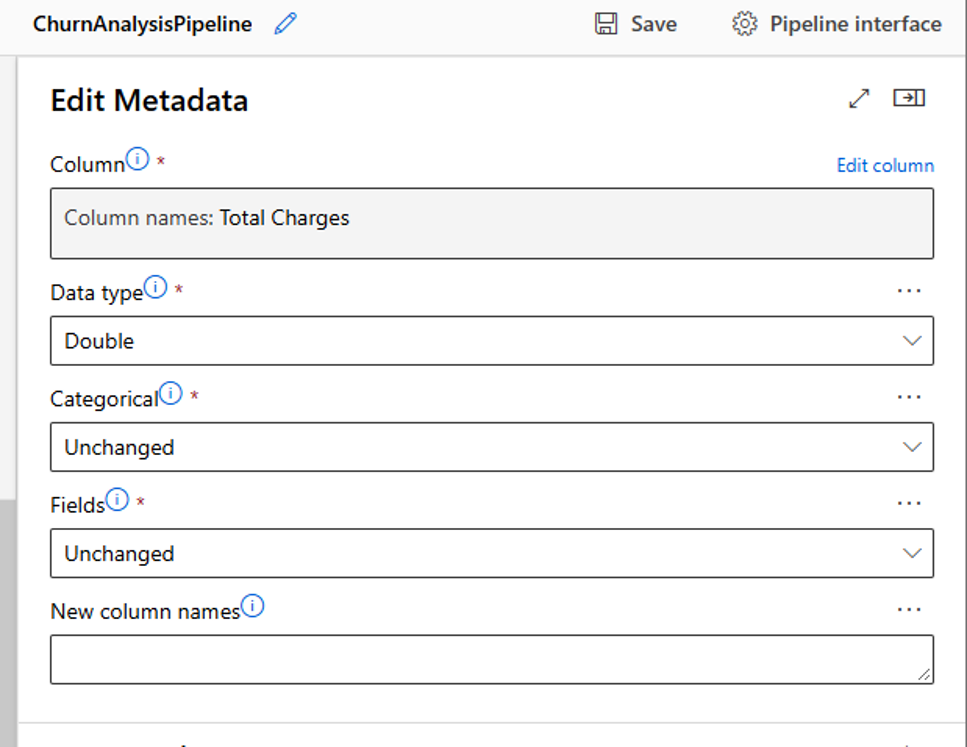

## Total Charges has no null values anymore

In [48]:
churn['Total Charges'].isnull().sum()

np.int64(0)

## A check on missing values
- Churn Reason has 5174 missing entries.
- These are the active customers whose churn Reason is not available.
- This column will be dropped for modelling to avoid data leakage

In [49]:
def information(df):
    df_information=pd.concat([df.dtypes, df.nunique(), df.isnull().sum()],\
                            keys=['Data Types', 'Number of Unique Values', 'Number of Missing Values'],\
                             axis=1)
    return df_information

In [50]:
information(churn)

,Data Types,Number of Unique Values,Number of Missing Values
CustomerID,object,7043,0
Count,int64,1,0
Country,object,1,0
State,object,1,0
City,object,1129,0
Zip Code,int64,1652,0
Lat Long,object,1652,0
Latitude,float64,1652,0
Longitude,float64,1651,0
Gender,object,2,0


## 	Duplicate records: Identify and count any duplicate records and handle them.
### This dataset has no duplicated rows

In [51]:
churn.duplicated().sum() 

np.int64(0)

#### In case if duplicated rows are present: use the following strategy

In [55]:
# create a copy of the dataset for future reference
churn_original=churn.copy()
churn_original.shape

(7043, 24)

In [56]:
churn[churn.duplicated()]

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason


In [57]:
# In case of dulpicates, save duplicates separately
dup_churn=churn[churn.duplicated()]
dup_churn

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason


In [58]:
# Since duplicates are saved separately, now delete them from the dataset
churn.drop_duplicates(inplace=True)
print('original records',churn_original.shape,'\nafter dropping duplicates:',churn.shape)

original records (7043, 24) 
after dropping duplicates: (7043, 24)


## Target Variable: 'Churn Value'
- It has two levels but datatype is int.
- It is a discrete binary variable, can be treated as categorical

In [52]:
churn['Churn Value'].value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

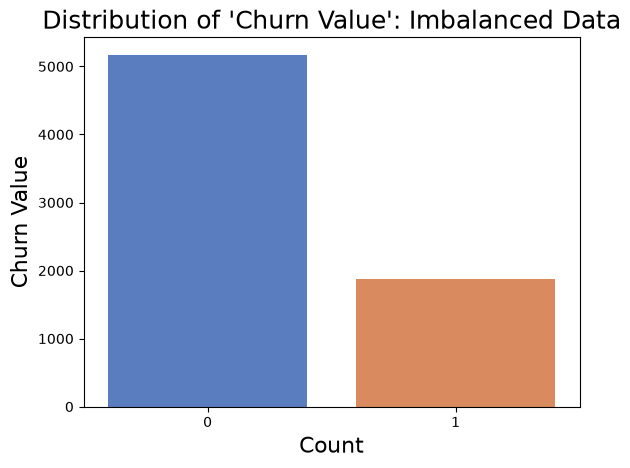

In [70]:
sns.barplot(churn['Churn Value'].value_counts(),orient='v', palette='muted' ) # create a barplot for them
plt.title("Distribution of 'Churn Value': Imbalanced Data", fontsize=18)
plt.ylabel('Churn Value', fontsize=16)
plt.xlabel("Count", fontsize=16)

plt.show()

## Drop columns with least information
- CustomerID
- Count
- Country
- State
- Zip Code
- Lat Long
- Latitude
- Longitude

In [53]:
cols= ['CustomerID','Count', 'Country', 'State','Zip Code','Lat Long', 'Latitude','Longitude']
churn.drop(columns=cols, inplace=True)
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,Los Angeles,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,Los Angeles,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,Los Angeles,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,Los Angeles,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,Los Angeles,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


### Drop 'Churn Label' as it represents the same information as 'Churn Value'

In [54]:
churn=churn.drop('Churn Label', axis=1)
churn.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV,Churn Reason
0,Los Angeles,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,86,3239,Competitor made better offer
1,Los Angeles,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,67,2701,Moved
2,Los Angeles,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,86,5372,Moved
3,Los Angeles,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,84,5003,Moved
4,Los Angeles,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1,89,5340,Competitor had better devices


### Univariate analysis: Conduct this analysis on all variables, creating appropriate visualizations.


#### Univariate analysis: Numerical Variables

#### Define numerical columns 

In [59]:
numerical_cols=churn.select_dtypes(include='number')
numerical_cols.head()

,Tenure Months,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV
0,2,53.85,108.15,1,86,3239
1,2,70.70,151.65,1,67,2701
2,8,99.65,820.50,1,86,5372
3,28,104.80,3046.05,1,84,5003
4,49,103.70,5036.30,1,89,5340


In [60]:
numerical_cols.shape

(7043, 6)

In [61]:
pd.options.display.max_columns=100
numerical_cols.describe().T

,count,mean,std,min,25%,50%,75%,max
Tenure Months,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
Monthly Charges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
Total Charges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80
Churn Value,7043.0,0.265370,0.441561,0.00,0.00,0.00,1.00,1.00
Churn Score,7043.0,58.699418,21.525131,5.00,40.00,61.00,75.00,100.00
CLTV,7043.0,4400.295755,1183.057152,2003.00,3469.00,4527.00,5380.50,6500.00


#### Plot numerical columns

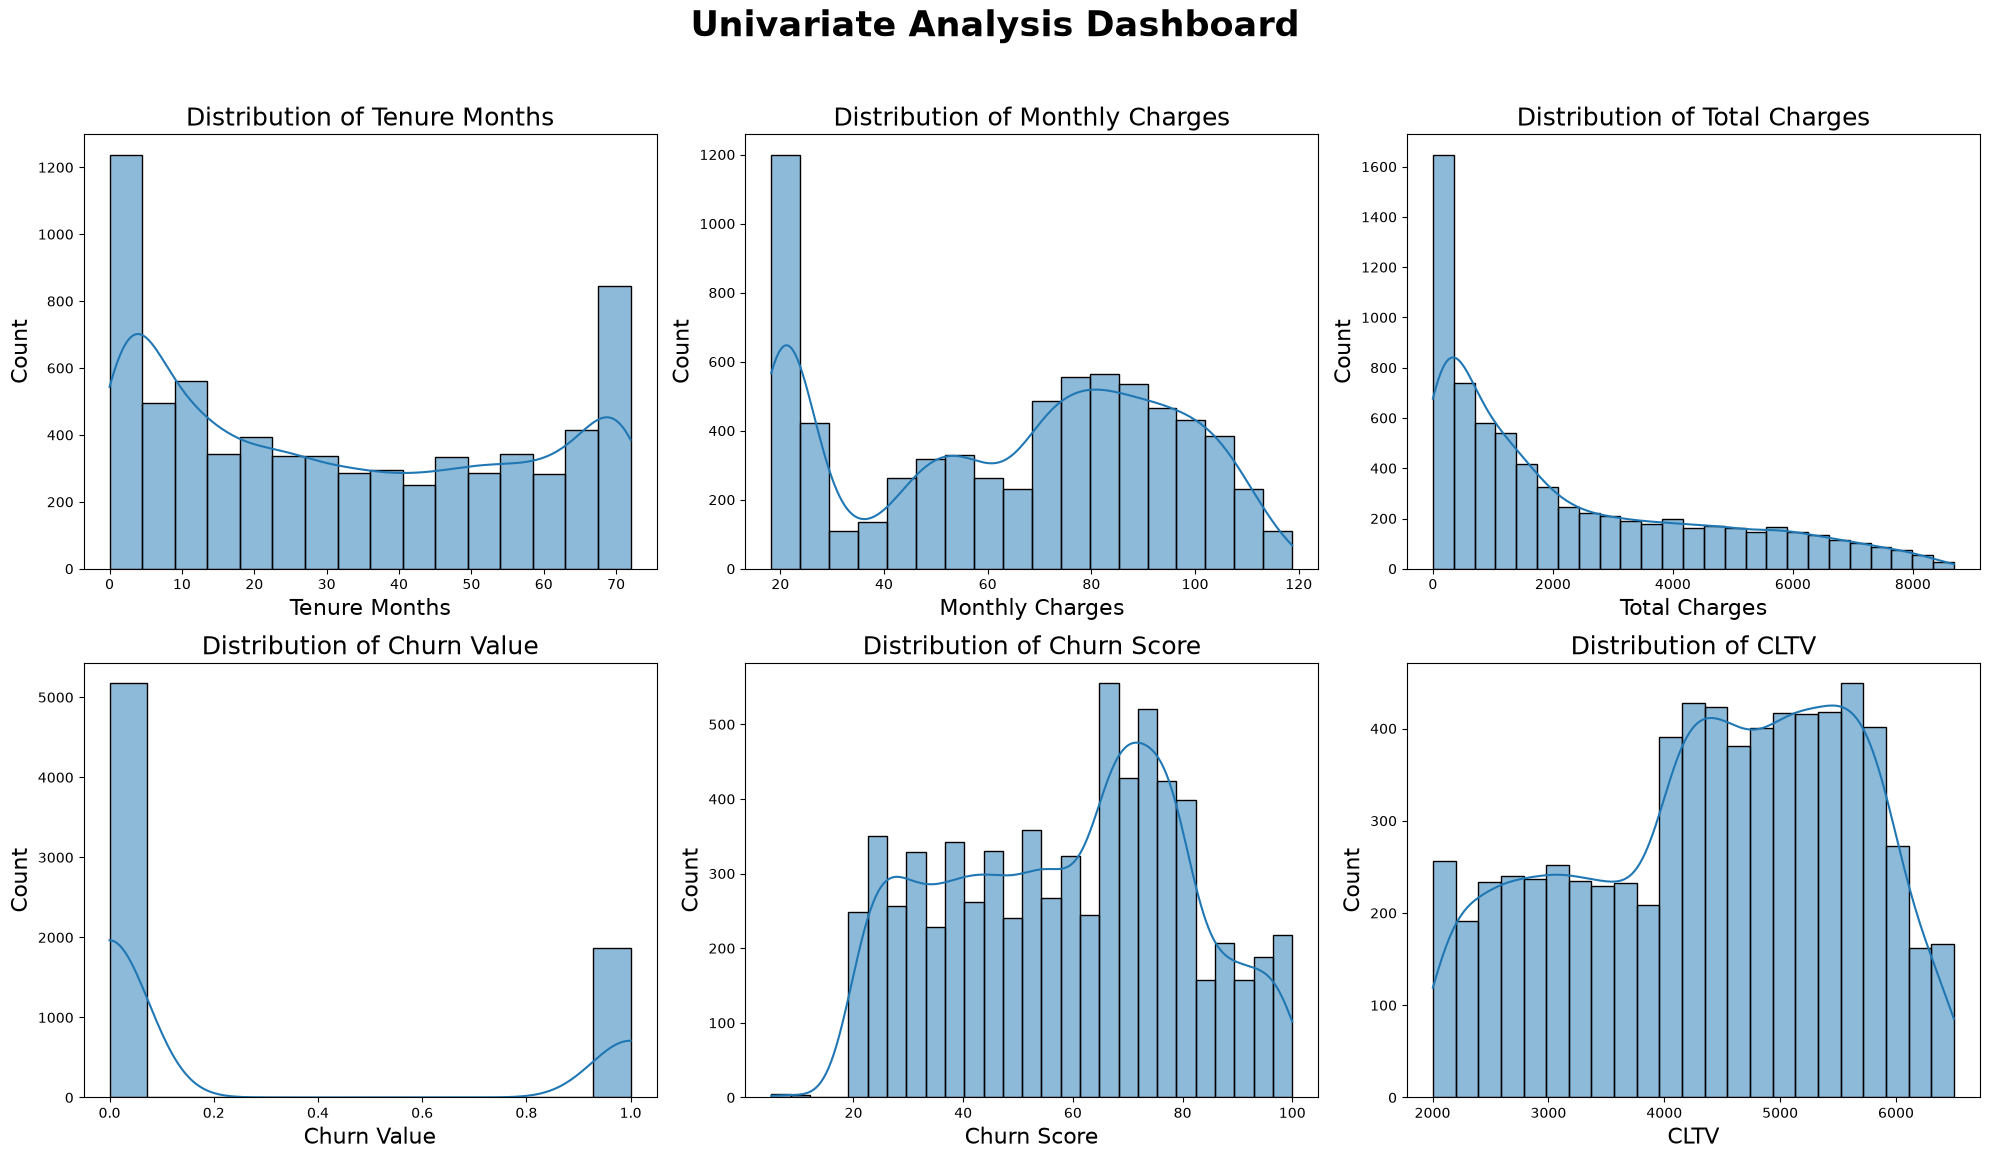

In [62]:
fig, axes=plt.subplots(3,3, figsize=(20,16))
axes=axes.flatten()


for i, var in enumerate(numerical_cols):
    sns.histplot(data=numerical_cols, x=var, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {var}", fontsize=18)
    axes[i].set_xlabel(f"{var}", fontsize=16)
    axes[i].set_ylabel("Count", fontsize=16)

for j in range(len(numerical_cols.columns), len(axes)):
    fig.delaxes(axes[j])


plt.suptitle("Univariate Analysis Dashboard", fontsize=25, weight='bold',y=1.02)
plt.tight_layout()
plt.show()

## Analysis:
-  Tenure Months: U-shaped histogram shows stay 0-5 months mostly or loyal customers around 70 months. If customers pass they initial months, they can be the loyal customers.
- Monthly Charges: Huge spike of customers paying basic plans of around 20Dollar  per month. Premium customers are paying $70 to $100 per month.
 <br>


- Total Charges: Total money spent over the lifetime is showing a spike around 0 means most of the customers are low tenure. Premium customers have spent $6000-$8000.
- Churn Value: Binary variable stored as numerical shows majority of the customers have stayed with the company.
- Churn Score: A major peak between 65 to 80 shows most of the customers have a moderate to high risk of churn.
- CLTV (Customer Lifetime Value): There is a peak around $4000 to $6000, means majority of the customers hold financial value


In [63]:
numerical_cols.skew().sort_values(ascending=False)

Churn Value        1.063031
Total Charges      0.963235
Tenure Months      0.239540
Churn Score       -0.089840
Monthly Charges   -0.220524
CLTV              -0.311602
dtype: float64

#### Analysis:
-  **Total Charges** has right skewness

## Define categorical columns

In [64]:
categorical_cols=churn.select_dtypes(include='object')
categorical_cols.head()

,City,Gender,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Churn Reason
0,Los Angeles,Male,No,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Competitor made better offer
1,Los Angeles,Female,No,No,Yes,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Moved
2,Los Angeles,Female,No,No,Yes,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,Moved
3,Los Angeles,Female,No,Yes,Yes,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,Moved
4,Los Angeles,Male,No,No,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),Competitor had better devices


In [65]:
categorical_cols.shape

(7043, 18)

## Plot categorical columns

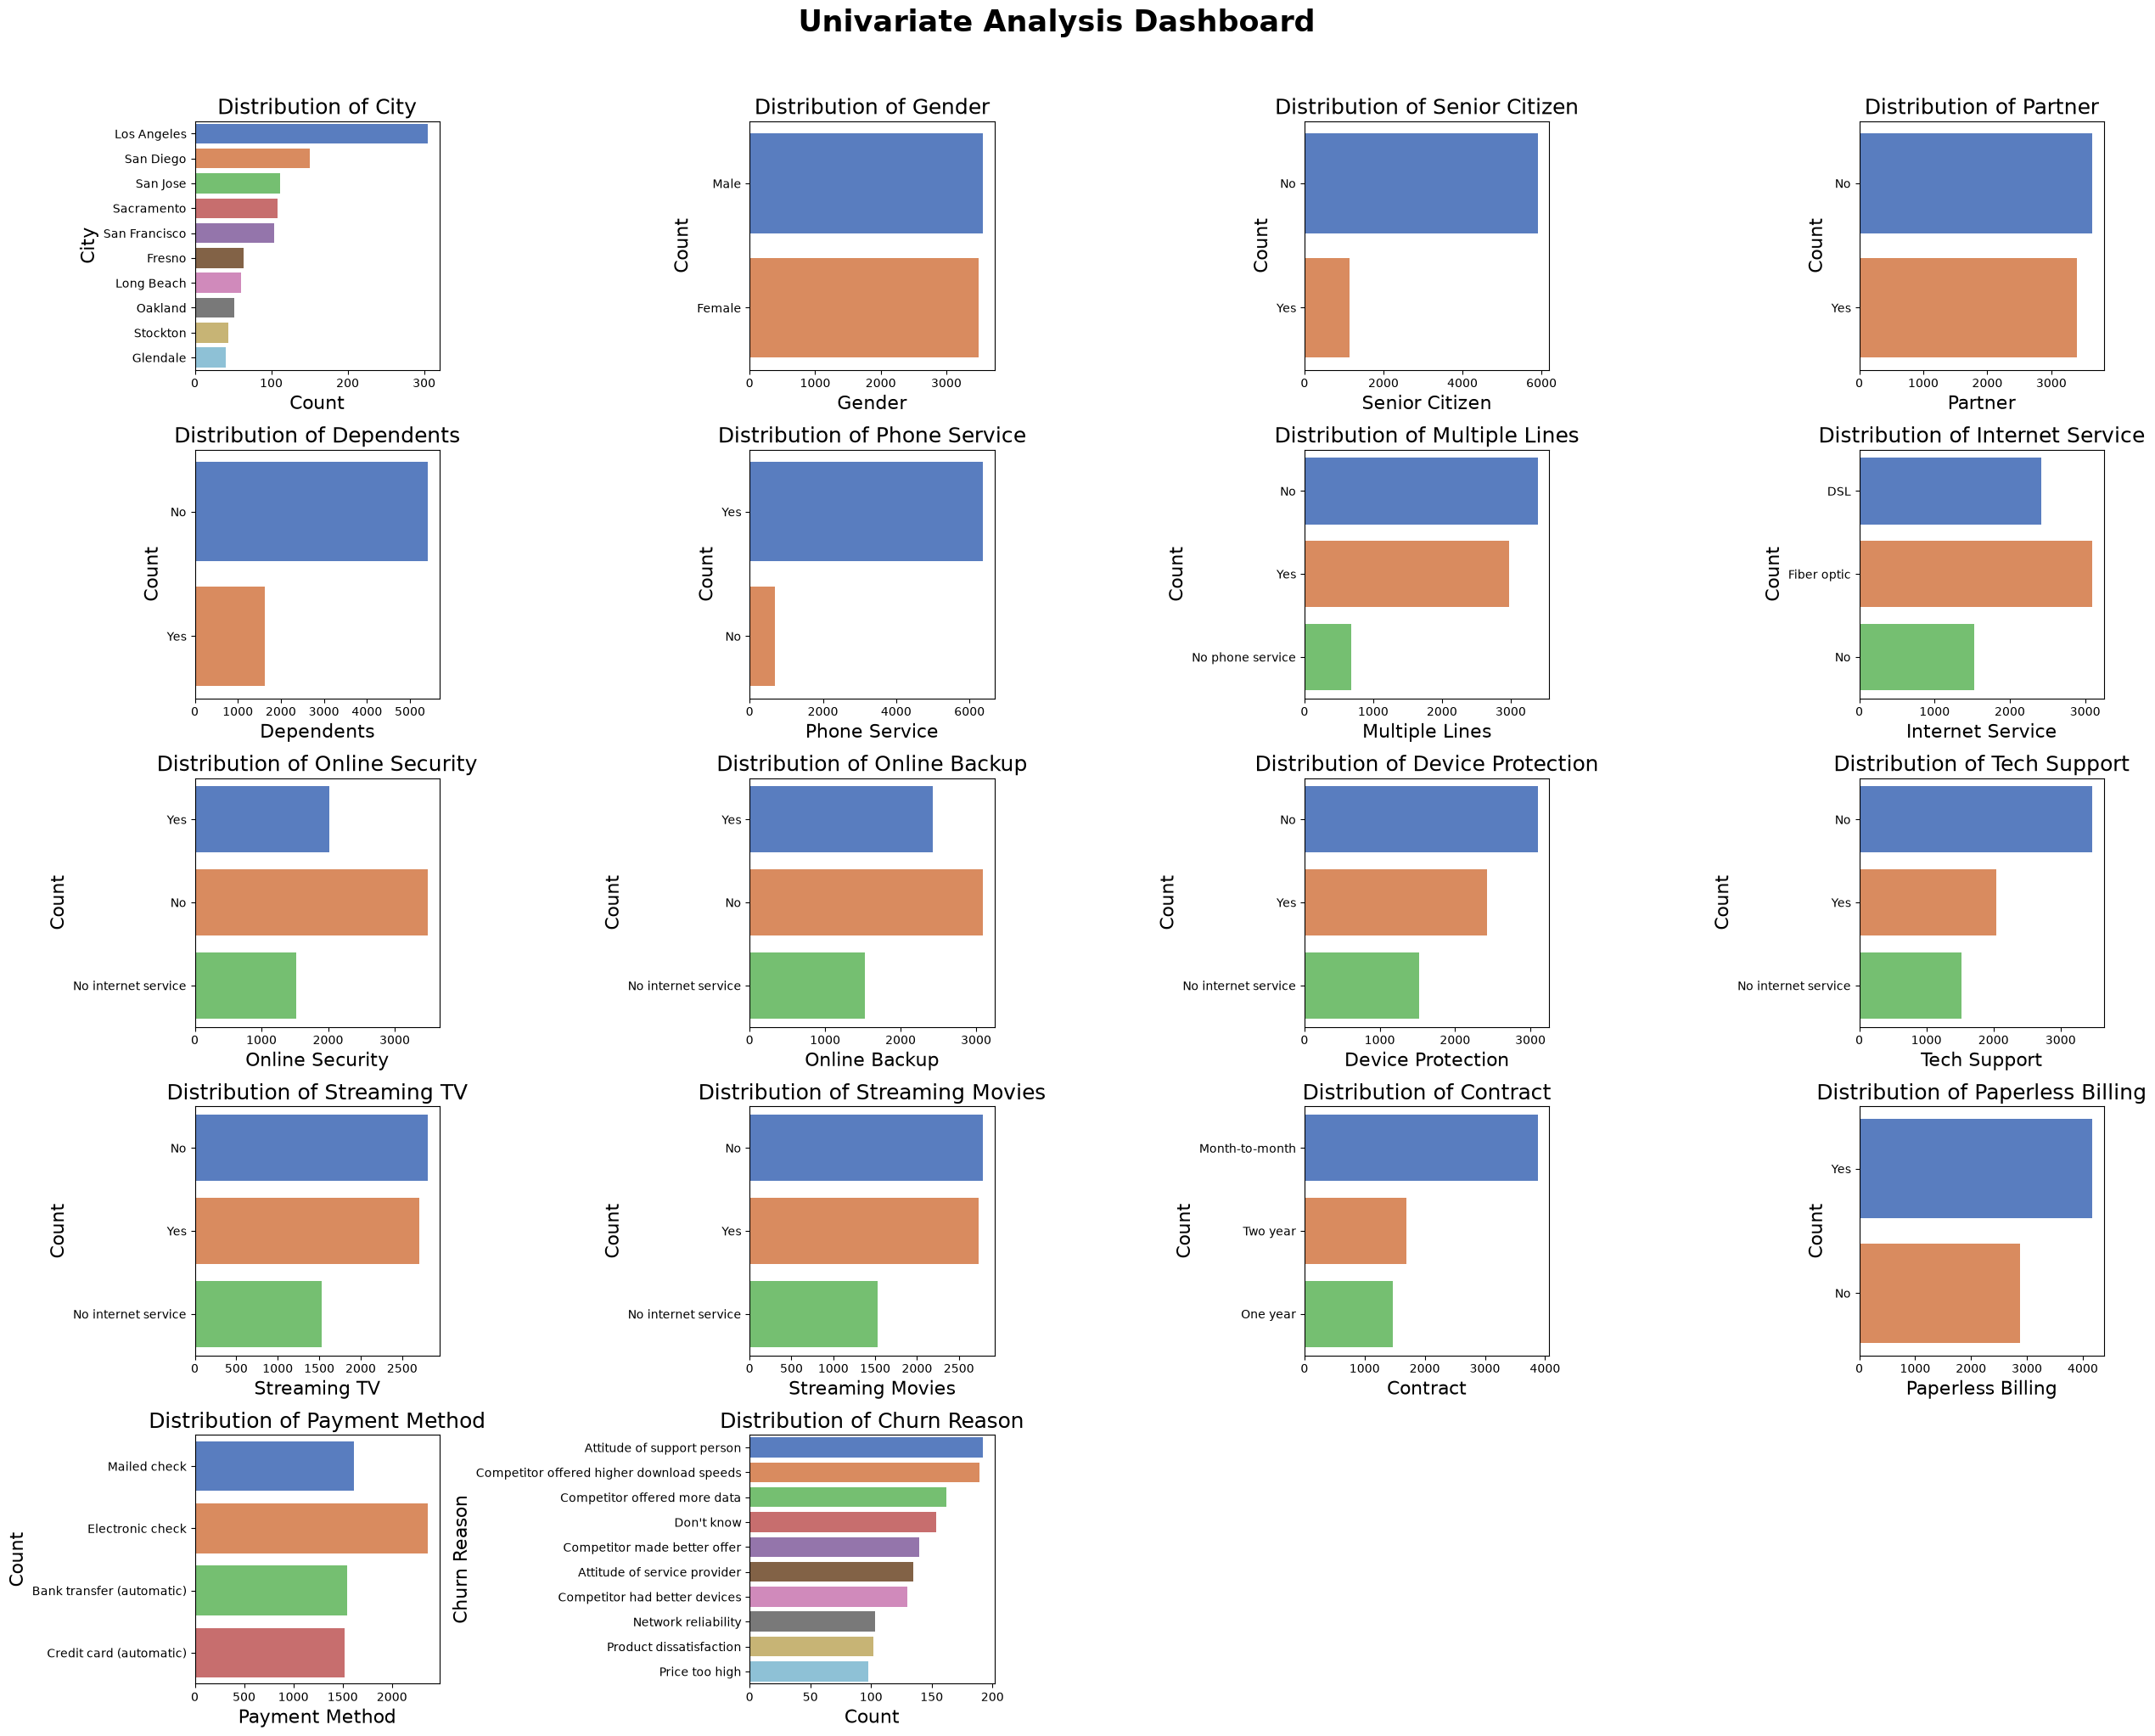

In [66]:
fig, axes=plt.subplots(5,4, figsize=(25,20))
axes=axes.flatten()

for i, var in enumerate(categorical_cols):
    if categorical_cols[var].nunique()>10: # if number of levels of a variable is more than 10
        top_10=categorical_cols[var].value_counts()[:10]
        sns.barplot(top_10,orient='h',ax=axes[i], palette='muted' ) # create a barplot for them
        axes[i].set_title(f"Distribution of {var}", fontsize=18)
        axes[i].set_ylabel(f"{var}", fontsize=16)
        axes[i].set_xlabel("Count", fontsize=16)
    else:
        sns.countplot(data=categorical_cols, y=var, ax=axes[i], palette="muted") #Otherwise create countplot
        axes[i].set_title(f"Distribution of {var}", fontsize=18)
        axes[i].set_xlabel(f"{var}", fontsize=16)
        axes[i].set_ylabel("Count", fontsize=16)

# Clean up empty subplots
for j in range(len(categorical_cols.columns),len(axes)):
     fig.delaxes(axes[j])

plt.suptitle("Univariate Analysis Dashboard", fontsize=25, weight='bold',y=1.02)
plt.tight_layout()
plt.show()

### Customer Demographics & Profile
- City: Most of the customers are from Los Angele and San Diego.
- Gender and Partner: Gender is a 50/50 ratio and so is the partner.
- Senior Citizen and Dependants: Majority of the customers are not senior citizen and do not have dependants.
### Core Telecom Services
- Phone and Multiple Lines: Most of the customers have phone service and massive majority has multiple lines.
- Internet Services: Fibre is more popular than DSL.
### Add-on Services
- Online Security, Online Backup, Device Protection, and Tech Support:
•	Most of the customers do not have these services. Unprotected customers who experience technical issues or data loss are much more likely to leave the company out of frustration.
### Billing, Contracts, & Risk Factors
- Contract: Most of the customers are month-to-month, they can cancel their services any time.
- Payment Method & Paperless Billing:  Most customers use paperless billing. Electronic Check is the most popular method; these are the high risk customers as they have to manually process the payment or think about the payment every month.
### Why Customers Leave: Churn Reason: 
Attitude of support person and competitor offered higher download speed are the top 2 reasons for customer churn.

# Correlation analysis to examine relationships between two numeric variables.

In [71]:
corr = numerical_cols.corr()
corr.style.background_gradient(cmap='coolwarm')
# 'RdBu_r', 'BrBG_r', & PuOr_r are other good diverging colormaps

,Tenure Months,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV
Tenure Months,1.000000,0.247900,0.826178,-0.352229,-0.224987,0.396406
Monthly Charges,0.247900,1.000000,0.651174,0.193356,0.133754,0.098693
Total Charges,0.826178,0.651174,1.000000,-0.198324,-0.123410,0.342091
Churn Value,-0.352229,0.193356,-0.198324,1.000000,0.664897,-0.127463
Churn Score,-0.224987,0.133754,-0.123410,0.664897,1.000000,-0.079782
CLTV,0.396406,0.098693,0.342091,-0.127463,-0.079782,1.000000


## Analysis
- There is a strong correlation between churn score and Churn Value i.e. +0.66
- Monthly Charges and Churn Value have a weak positive correlation of 0.19.
- Tenure Months and Total Charges have high correlation of +0.83 means longer the tenure with the company, higher are the charges.


## Separate features and target
- Churn Value is the target variable, so drop it
- Drop  Churn Score, Churn Reason, CLTV entirely before training the model because they cause direct data leakage.

In [172]:
churn_copy=churn.copy()

In [173]:
columns_to_drop=['Churn Value','Churn Score','Churn Reason','CLTV']

In [174]:
X=churn.drop(columns=columns_to_drop) # all the columns except target
y=churn['Churn Value']

In [175]:
# Split into train and test sets FIRST to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Azure: Split Data with 80:20 and Stratification
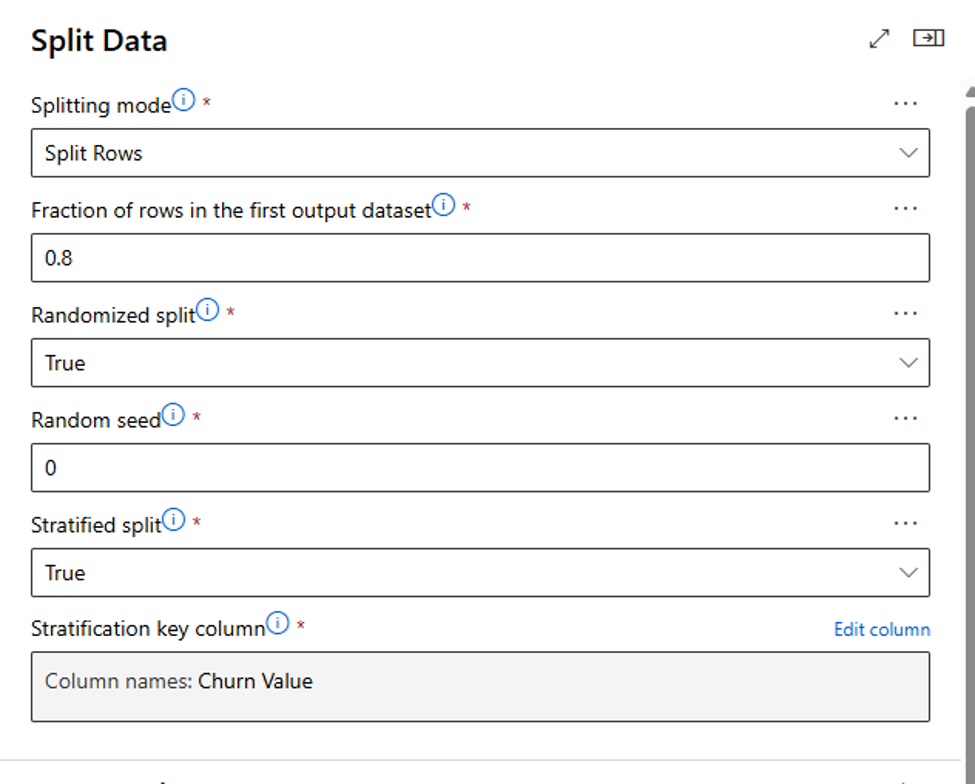

In [132]:
X_train.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,City_Encoded
4626,Apple Valley,Male,No,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65,0.311770
4192,Glenn,Male,No,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55,0.224365
5457,Cottonwood,Male,No,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,0.262774
4717,Westminster,Female,No,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70,0.220779
4673,Hemet,Male,No,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55,0.220883


In [133]:
X_test.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,City_Encoded
2196,Barstow,Male,No,Yes,No,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0.227713
3549,Somis,Female,Yes,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0.327342
3515,Anaheim,Female,No,Yes,No,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0.189307
5162,Copperopolis,Male,No,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0.224365
4642,Hesperia,Female,No,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0.224365


In [177]:
X_train.select_dtypes(include='object').columns

Index(['City', 'Gender', 'Senior Citizen', 'Partner', 'Dependents',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method'],
      dtype='object')

## One Hot Encode Categorical columns

In [178]:
categorical_cols=X_train.select_dtypes(include='object').columns
encoder = OneHotEncoder(handle_unknown='ignore', #drop='first', 
                        #sparse=False
                       sparse_output=False 
                       )

'''
drop='first' → avoids dummy variable trap

handle_unknown='ignore' → prevents crash on new categories in test data

sparse=False → returns DataFrame-friendly output
'''

#FIT on TRAIN ONLY (no data leakage)
encoder.fit(X_train[categorical_cols])

#Transform Train & Test
X_train_encoded = encoder.transform(X_train[categorical_cols])
X_test_encoded  = encoder.transform(X_test[categorical_cols])

#Convert back to DataFrame with proper column names
encoded_cols = encoder.get_feature_names_out(categorical_cols)

X_train_encoded_df = pd.DataFrame(X_train_encoded, columns=encoded_cols, index=X_train.index)
X_test_encoded_df  = pd.DataFrame(X_test_encoded,  columns=encoded_cols, index=X_test.index)

# Drop original categorical columns & attach encoded ones
X_train_2 = X_train.drop(columns=categorical_cols)
X_test_2  = X_test.drop(columns=categorical_cols)

X_train_encoded = pd.concat([X_train_2, X_train_encoded_df], axis=1)
X_test_encoded  = pd.concat([X_test_2, X_test_encoded_df], axis=1)

## Azure: convert Categorical columns to 0 and 1
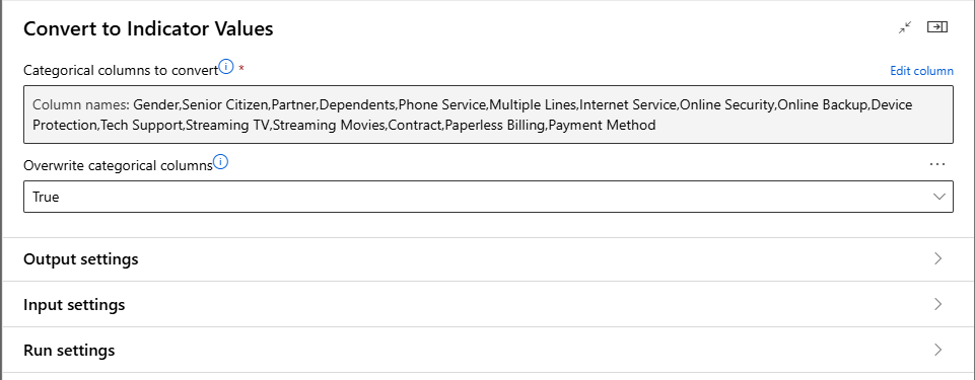

In [217]:
X_train_encoded.head()

,Tenure Months,Monthly Charges,Total Charges,City_Acampo,City_Acton,City_Adelanto,City_Adin,City_Agoura Hills,City_Aguanga,City_Ahwahnee,City_Alameda,City_Alamo,City_Albany,City_Albion,City_Alderpoint,City_Alhambra,City_Aliso Viejo,City_Alleghany,City_Alpaugh,City_Alpine,City_Alta,City_Altadena,City_Alturas,City_Alviso,City_Amador City,City_Amboy,City_Anaheim,City_Anderson,City_Angels Camp,City_Angelus Oaks,City_Angwin,City_Annapolis,City_Antelope,City_Antioch,City_Anza,City_Apple Valley,City_Applegate,City_Aptos,City_Arbuckle,City_Arcadia,City_Arcata,City_Armona,City_Arnold,City_Aromas,City_Arroyo Grande,City_Artesia,City_Arvin,City_Atascadero,City_Atherton,City_Atwater,...,City_Yosemite National Park,City_Yountville,City_Yreka,City_Yuba City,City_Yucaipa,City_Yucca Valley,City_Zenia,Gender_Female,Gender_Male,Senior Citizen_No,Senior Citizen_Yes,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,Phone Service_No,Phone Service_Yes,Multiple Lines_No,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_DSL,Internet Service_Fiber optic,Internet Service_No,Online Security_No,Online Security_No internet service,Online Security_Yes,Online Backup_No,Online Backup_No internet service,Online Backup_Yes,Device Protection_No,Device Protection_No internet service,Device Protection_Yes,Tech Support_No,Tech Support_No internet service,Tech Support_Yes,Streaming TV_No,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,Paperless Billing_No,Paperless Billing_Yes,Payment Method_Bank transfer (automatic),Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
4626,35,49.20,1701.65,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4192,15,75.10,1151.55,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
5457,13,40.55,590.35,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4717,26,73.50,1905.70,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
4673,1,44.55,44.55,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [180]:
X_train_encoded.columns

Index(['Tenure Months', 'Monthly Charges', 'Total Charges', 'City_Acampo',
       'City_Acton', 'City_Adelanto', 'City_Adin', 'City_Agoura Hills',
       'City_Aguanga', 'City_Ahwahnee',
       ...
       'Streaming Movies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'Paperless Billing_No', 'Paperless Billing_Yes',
       'Payment Method_Bank transfer (automatic)',
       'Payment Method_Credit card (automatic)',
       'Payment Method_Electronic check', 'Payment Method_Mailed check'],
      dtype='object', length=1174)

In [181]:
X_test_encoded.columns

Index(['Tenure Months', 'Monthly Charges', 'Total Charges', 'City_Acampo',
       'City_Acton', 'City_Adelanto', 'City_Adin', 'City_Agoura Hills',
       'City_Aguanga', 'City_Ahwahnee',
       ...
       'Streaming Movies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'Paperless Billing_No', 'Paperless Billing_Yes',
       'Payment Method_Bank transfer (automatic)',
       'Payment Method_Credit card (automatic)',
       'Payment Method_Electronic check', 'Payment Method_Mailed check'],
      dtype='object', length=1174)

## Scaling

In [182]:
scaler=MinMaxScaler()
X_train_scaled=scaler.fit_transform(X_train_encoded)
X_test_scaled=scaler.transform(X_test_encoded)
X_train_scaled_df=pd.DataFrame(X_train_scaled,columns=X_train_encoded.columns)
X_test_scaled_df=pd.DataFrame(X_test_scaled,columns=X_test_encoded.columns)
X_train_scaled_df.head()

,Tenure Months,Monthly Charges,Total Charges,City_Acampo,City_Acton,City_Adelanto,City_Adin,City_Agoura Hills,City_Aguanga,City_Ahwahnee,City_Alameda,City_Alamo,City_Albany,City_Albion,City_Alderpoint,City_Alhambra,City_Aliso Viejo,City_Alleghany,City_Alpaugh,City_Alpine,City_Alta,City_Altadena,City_Alturas,City_Alviso,City_Amador City,City_Amboy,City_Anaheim,City_Anderson,City_Angels Camp,City_Angelus Oaks,City_Angwin,City_Annapolis,City_Antelope,City_Antioch,City_Anza,City_Apple Valley,City_Applegate,City_Aptos,City_Arbuckle,City_Arcadia,City_Arcata,City_Armona,City_Arnold,City_Aromas,City_Arroyo Grande,City_Artesia,City_Arvin,City_Atascadero,City_Atherton,City_Atwater,...,City_Yosemite National Park,City_Yountville,City_Yreka,City_Yuba City,City_Yucaipa,City_Yucca Valley,City_Zenia,Gender_Female,Gender_Male,Senior Citizen_No,Senior Citizen_Yes,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,Phone Service_No,Phone Service_Yes,Multiple Lines_No,Multiple Lines_No phone service,Multiple Lines_Yes,Internet Service_DSL,Internet Service_Fiber optic,Internet Service_No,Online Security_No,Online Security_No internet service,Online Security_Yes,Online Backup_No,Online Backup_No internet service,Online Backup_Yes,Device Protection_No,Device Protection_No internet service,Device Protection_Yes,Tech Support_No,Tech Support_No internet service,Tech Support_Yes,Streaming TV_No,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,Paperless Billing_No,Paperless Billing_Yes,Payment Method_Bank transfer (automatic),Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,0.486111,0.306926,0.195934,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.208333,0.565022,0.132594,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.180556,0.220727,0.067975,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3,0.361111,0.549078,0.219429,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
4,0.013889,0.260588,0.005130,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


## Azure: Normalize Data with MinMaxScaler
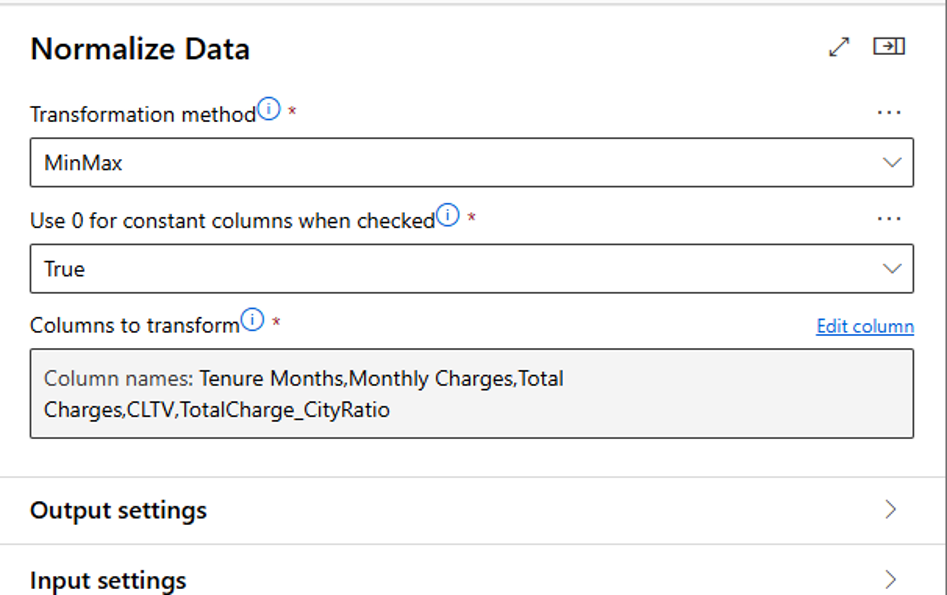

# Azure Pipeline for Cleaning, Normalization and Splitting
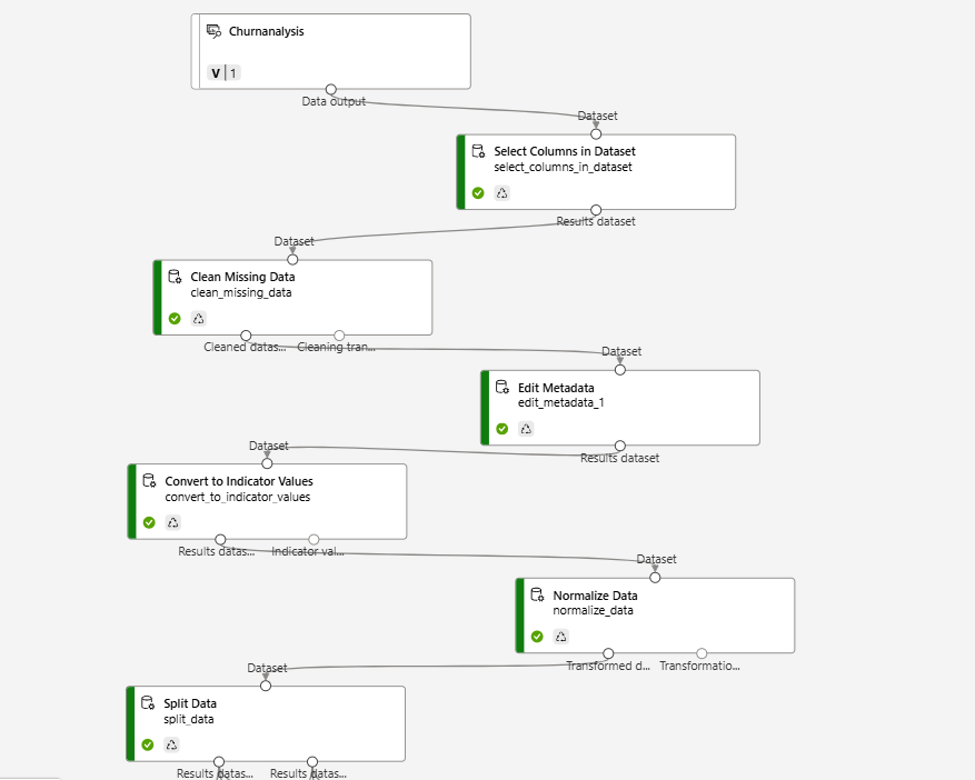

## Logistic Regression

In [190]:
#step1. create an instanse
model_LR = LogisticRegression(random_state=42, penalty='l2')

#step2. train (fit) model
model_LR.fit(X_train_scaled_df,y_train)


#step 3. predict on train and test set
y_pred_LR_train = model_LR.predict(X_train_scaled_df)
y_pred_LR_test = model_LR.predict(X_test_scaled_df)
y_pred_probs_LR = model_LR.predict_proba(X_test_scaled_df)

##  Print Classification Report

In [192]:
print(classification_report(y_test, y_pred_LR_test))

              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.62      0.55      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



## Confusion Matrix

In [195]:
cm_matrix_Log=confusion_matrix(y_test,y_pred_LR_test, labels=[1,0]).T
print(cm_matrix_Log)

[[204 124]
 [170 911]]


## Plot Confusion Matrix

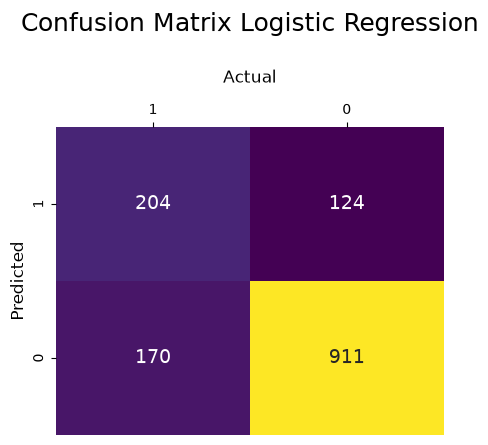

In [208]:
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_matrix_Log, 
    annot=True, 
    fmt='d', 
    cmap='viridis',    # Matches the color palette in your screenshot
    cbar=False,
    xticklabels=['1', '0'], 
    yticklabels=['1', '0'],
    annot_kws={"size": 14}
)

# Labelling and Titles
plt.title('Confusion Matrix Logistic Regression\n', fontsize=18)
plt.xlabel("Actual", fontsize=12, labelpad=15)
plt.ylabel("Predicted", fontsize=12)
plt.gca().xaxis.set_label_position('top')  # Pushes "Actual" text to the top
plt.gca().xaxis.tick_top()                 # Pushes the 1 and 0 marks to the top

plt.show()

# Azure Output
## Logistic Regression
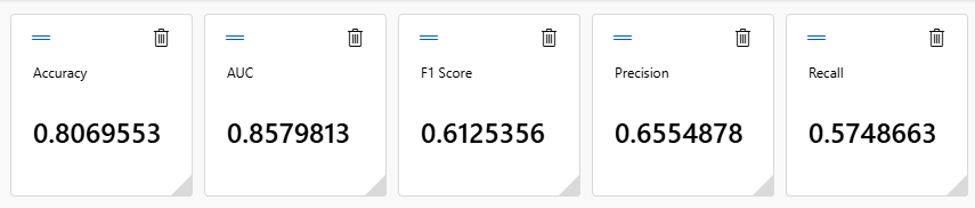
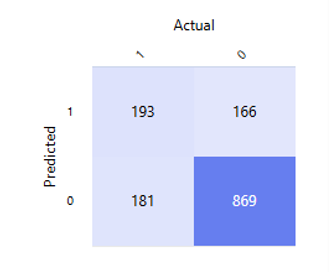

# Analysis
- ## Support column in Jupyter notebook shows exactly 1,035 for Class 0 and 374 for Class 1.
- ## This is a 1:1 exact match with the row split that Azure ML calculated with stratified split
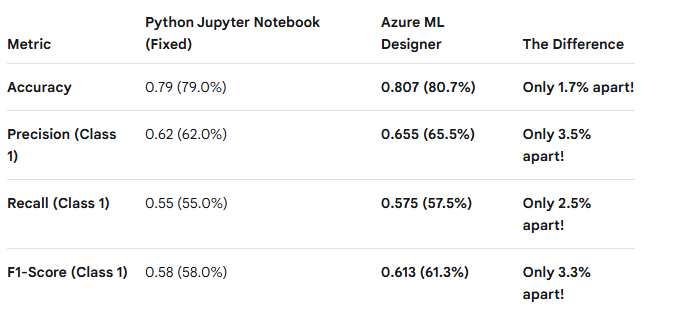

# RandomForestClassifier

## Initialize Model

In [199]:
model_RF=RandomForestClassifier(n_estimators=100, # Number of decision trees to create
                               max_depth=32, # Maximum depth of the trees to prevent deep overfitting
                               random_state=42,  # Random seed to lock in row shuffling reproducibility
                               n_jobs=-1) # Uses all available CPU cores for faster execution

## Train Model

In [200]:
model_RF.fit(X_train_scaled_df,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",32
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

# Predict on train and test set

In [201]:
y_pred_RF_train = model_RF.predict(X_train_scaled_df)
y_pred_RF_test = model_RF.predict(X_test_scaled_df)

##  Print Classification Report

In [202]:
print("--- TWO-CLASS DECISION FOREST PERFORMANCE ---")
print(classification_report(y_test, y_pred_RF_test))

--- TWO-CLASS DECISION FOREST PERFORMANCE ---
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



## Confusion Matrix

In [203]:
cm_matrix_RF=confusion_matrix(y_test,y_pred_RF_test, labels=[1,0]).T
print(cm_matrix_RF)

[[203 107]
 [171 928]]


## Plot Confusion Matrix

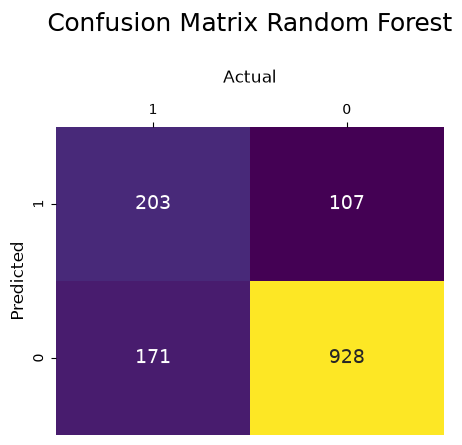

In [209]:
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_matrix_RF, 
    annot=True, 
    fmt='d', 
    cmap='viridis',    # Matches the color palette in your screenshot
    cbar=False,
    xticklabels=['1', '0'], 
    yticklabels=['1', '0'],
    annot_kws={"size": 14}
)

# Labelling and titles
plt.title('Confusion Matrix Random Forest\n', fontsize=18)
plt.xlabel("Actual", fontsize=12, labelpad=15)
plt.ylabel("Predicted", fontsize=12)
plt.gca().xaxis.set_label_position('top')  # Pushes "Actual" text to the top
plt.gca().xaxis.tick_top()                 # Pushes the 1 and 0 marks to the top

plt.show()

# Azure Output
## Random Forest
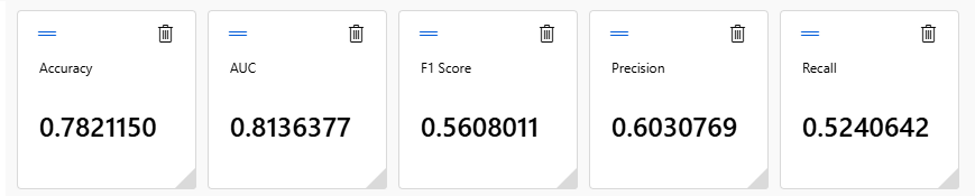
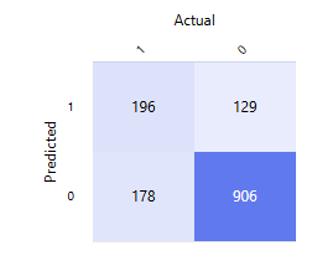

# Analysis
- **Local Python Random Forest** model outperformed Azure ML Designer pipeline in this test for Class 1 prediction
- **AzureML** limits tree growth earlier while max_depth in notebook is 32
-  **This allows to extract higher performance**
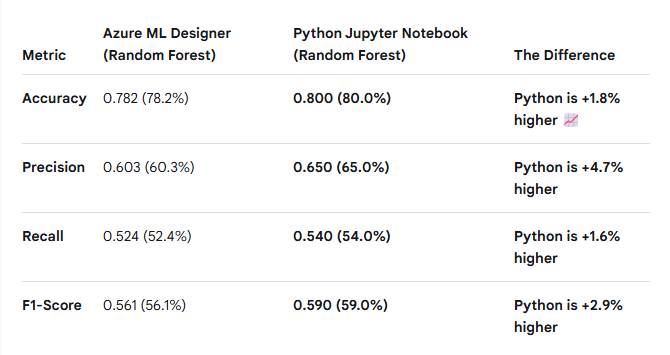

## Support Vector Classifier (SVC)
### Initialize the model

In [210]:
model_svc=SVC(kernel='linear', #linear boundary hyperplane
             C=1.0, # Regularization parameter
             probability=True, #  probability estimation so scikit-learn can calculate AUC
             random_state=42)

## Train Model

In [211]:
model_svc.fit(X_train_scaled_df,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


## Predict on Train and Test

In [212]:
y_pred_SVC_train = model_svc.predict(X_train_scaled_df)
y_pred_SVC_test = model_svc.predict(X_test_scaled_df)

##  Print Classification Report

In [213]:
print("--- TWO-CLASS SUPPORT VECTOR MACHINES PERFORMANCE ---")
print(classification_report(y_test, y_pred_SVC_test))

--- TWO-CLASS SUPPORT VECTOR MACHINES PERFORMANCE ---
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.61      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



## Confusion Matrix

In [214]:
cm_matrix_SVC=confusion_matrix(y_test,y_pred_SVC_test, labels=[1,0]).T
print(cm_matrix_SVC)

[[197 125]
 [177 910]]


## Plot Confusion Matrix

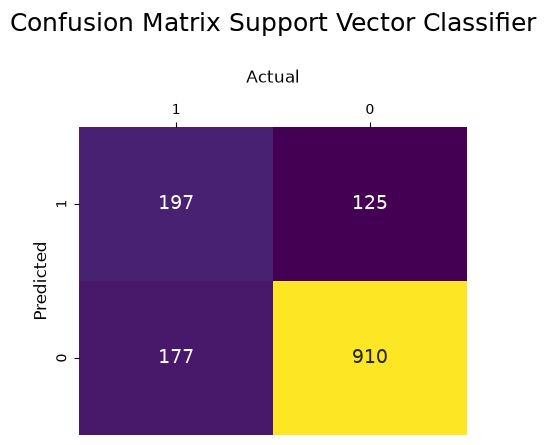

In [215]:
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_matrix_SVC, 
    annot=True, 
    fmt='d', 
    cmap='viridis',    # Matches the color palette in your screenshot
    cbar=False,
    xticklabels=['1', '0'], 
    yticklabels=['1', '0'],
    annot_kws={"size": 14}
)

# Labelling and title
plt.title('Confusion Matrix Support Vector Classifier\n', fontsize=18)
plt.xlabel("Actual", fontsize=12, labelpad=15)
plt.ylabel("Predicted", fontsize=12)
plt.gca().xaxis.set_label_position('top')  # Pushes "Actual" text to the top
plt.gca().xaxis.tick_top()                 # Pushes the 1 and 0 marks to the top

plt.show()

# Azure Output
## Support Vector Calssifier
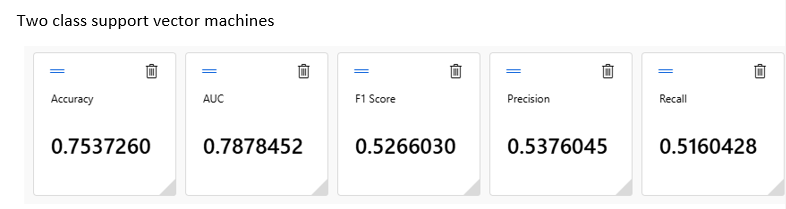
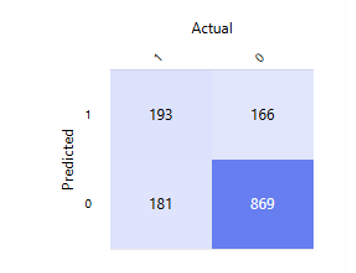

## Analysis
- Python Jupyter Notebook code outperformed the default Azure ML Designer setup
- 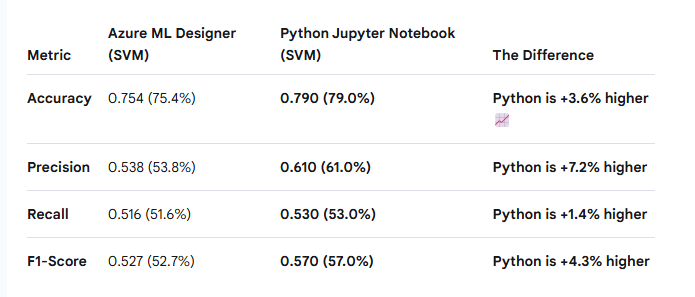

# Azure Pipeline for Modelling
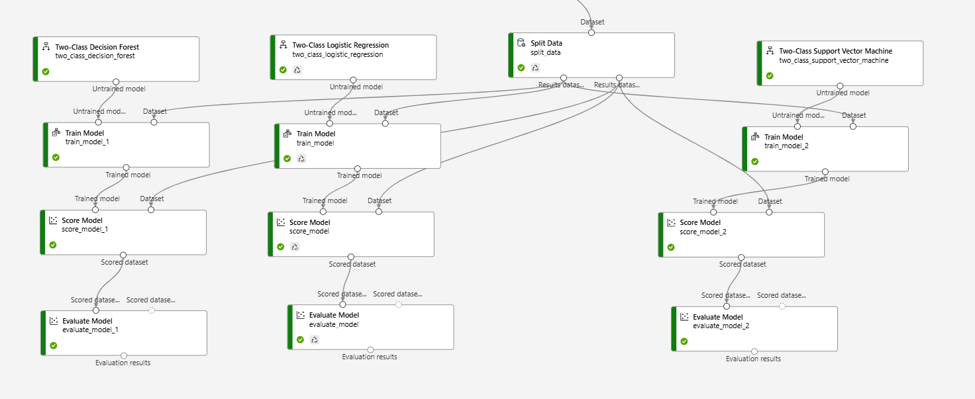

# Announcement of Winner

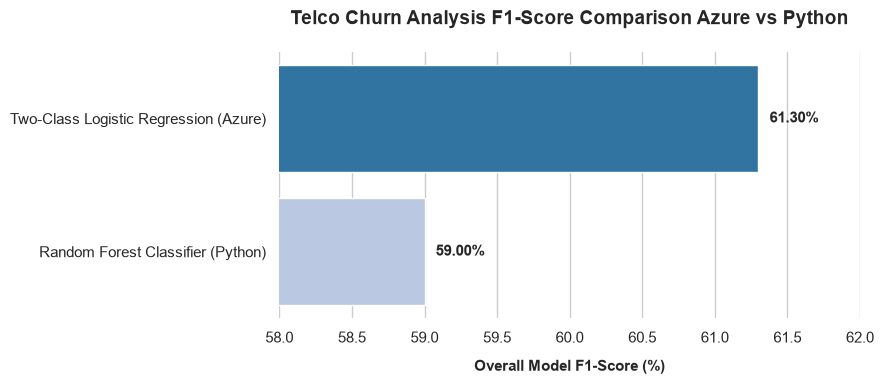

In [219]:
# 1. Structure your classification results into a DataFrame
# Scores taken directly from your classification report outputs
summary_data = {
    'Model Configuration': [
        'Two-Class Logistic Regression (Azure)', 
        'Random Forest Classifier (Python)'
    ],
    'Testing F1_Score': [0.613, 0.59] 
}
df_clf_perf = pd.DataFrame(summary_data)

# Convert raw scores to percentages
df_clf_perf['F1_Score (%)'] = df_clf_perf['Testing F1_Score'] * 100

# 2. Initialize the Seaborn Visual Layout
plt.figure(figsize=(9, 4))
sns.set_theme(style="whitegrid")

# Create the bar plot
# Deep blue highlights the winning Logistic Regression model
ax = sns.barplot(
    data=df_clf_perf,
    x='F1_Score (%)',
    y='Model Configuration',
    hue='Model Configuration',
    palette={'Two-Class Logistic Regression (Azure)': '#1f77b4', 
             'Random Forest Classifier (Python)': '#b4c6e7'},
    legend=False
)
# 3. Overlay precise value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=8, weight='bold', size=11)

# 4. Presentation framing and cleanup
plt.title("Telco Churn Analysis F1-Score Comparison Azure vs Python", fontsize=14, pad=20, weight='bold')
plt.xlabel("Overall Model F1-Score (%)", fontsize=11, labelpad=10, weight='bold')
plt.ylabel("") # Cleared for cleaner aesthetic look

# Constrain the X-axis boundary to match the regression chart spacing
plt.xlim(58,62)

# Strip away chart borders for a polished presentation look
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## Analysis:
- Azure: Two-Class Logistic Regression is the winner with 61.30% performance

- Python: Random forest Classifier is the winner with 59% performance

- Reason: Slight difference in results is due to random state, groups chosen in two environments are different


## Real-Time Inference Pipeline
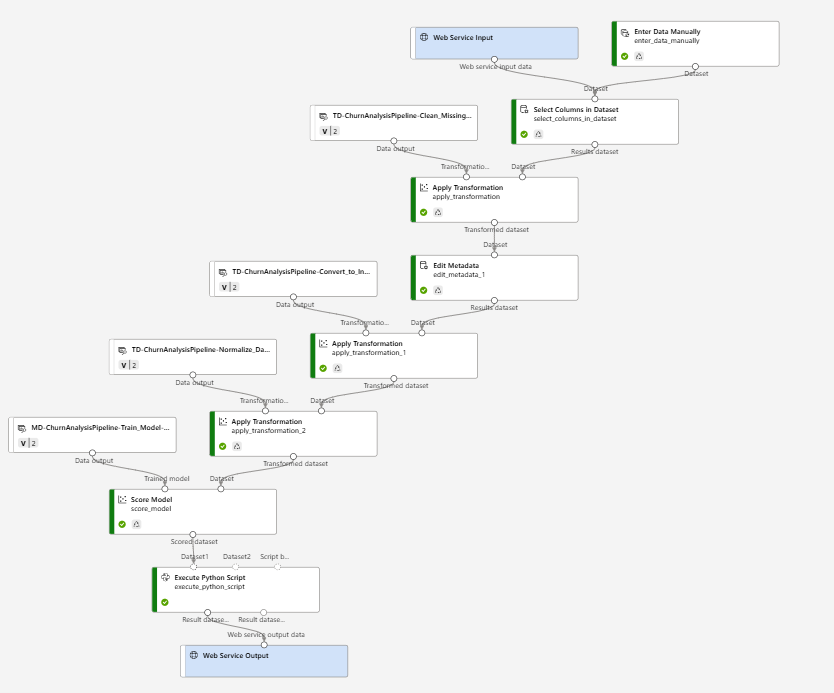

## Deployment in Azure for Logistic Regression
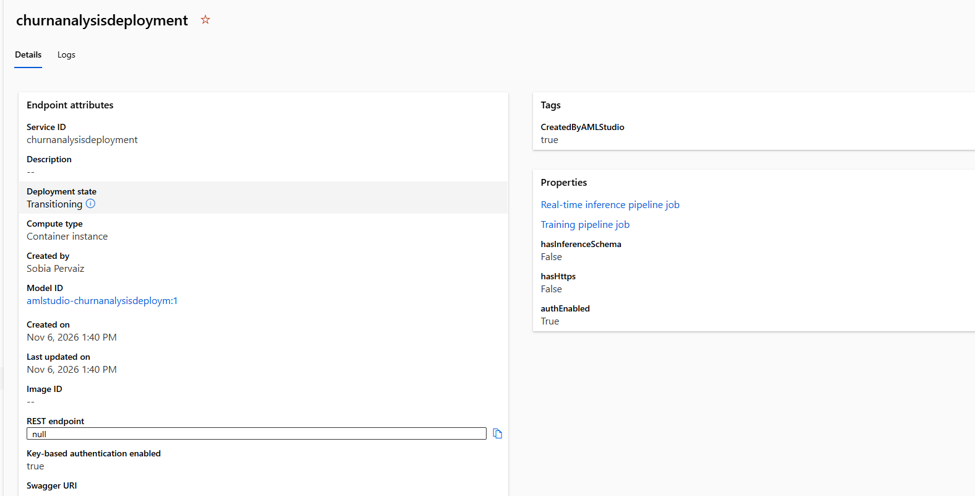

# AutoML
# Dataset selection
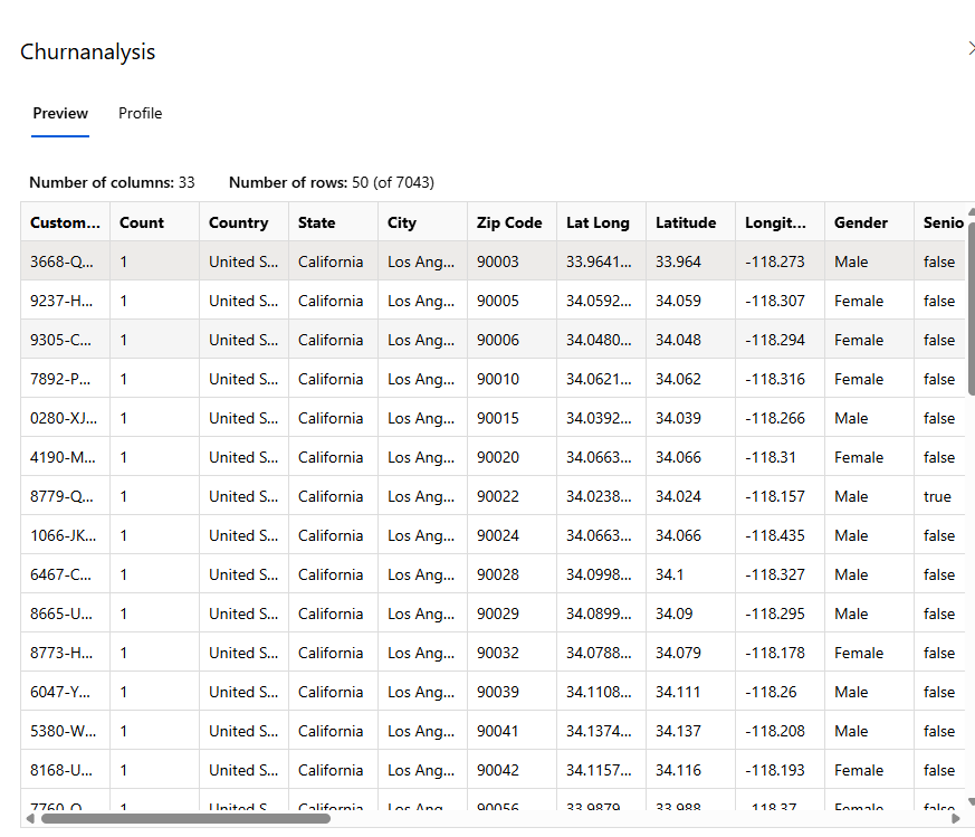

# Task type as classification
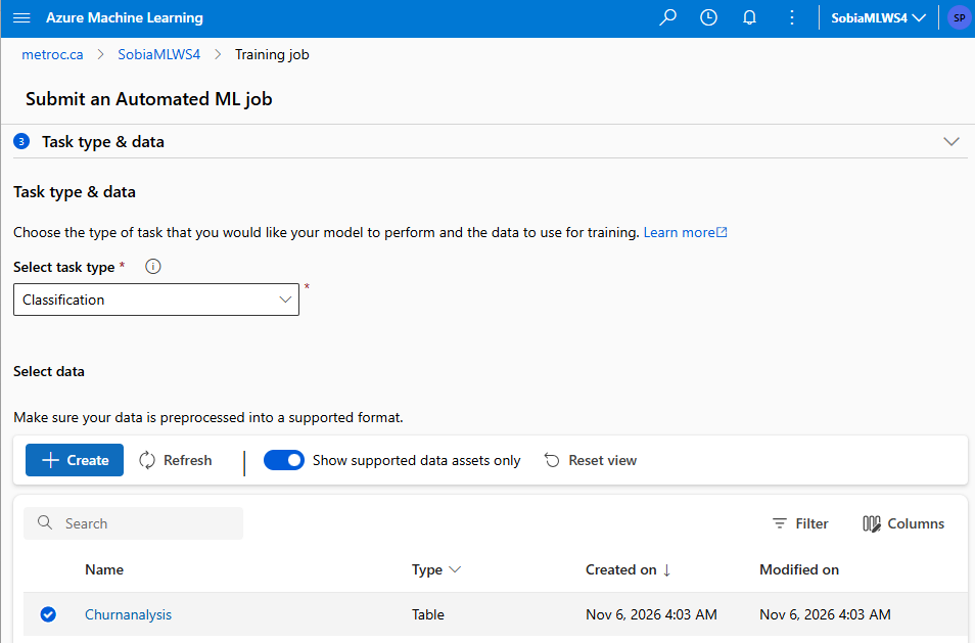

# Target column selection
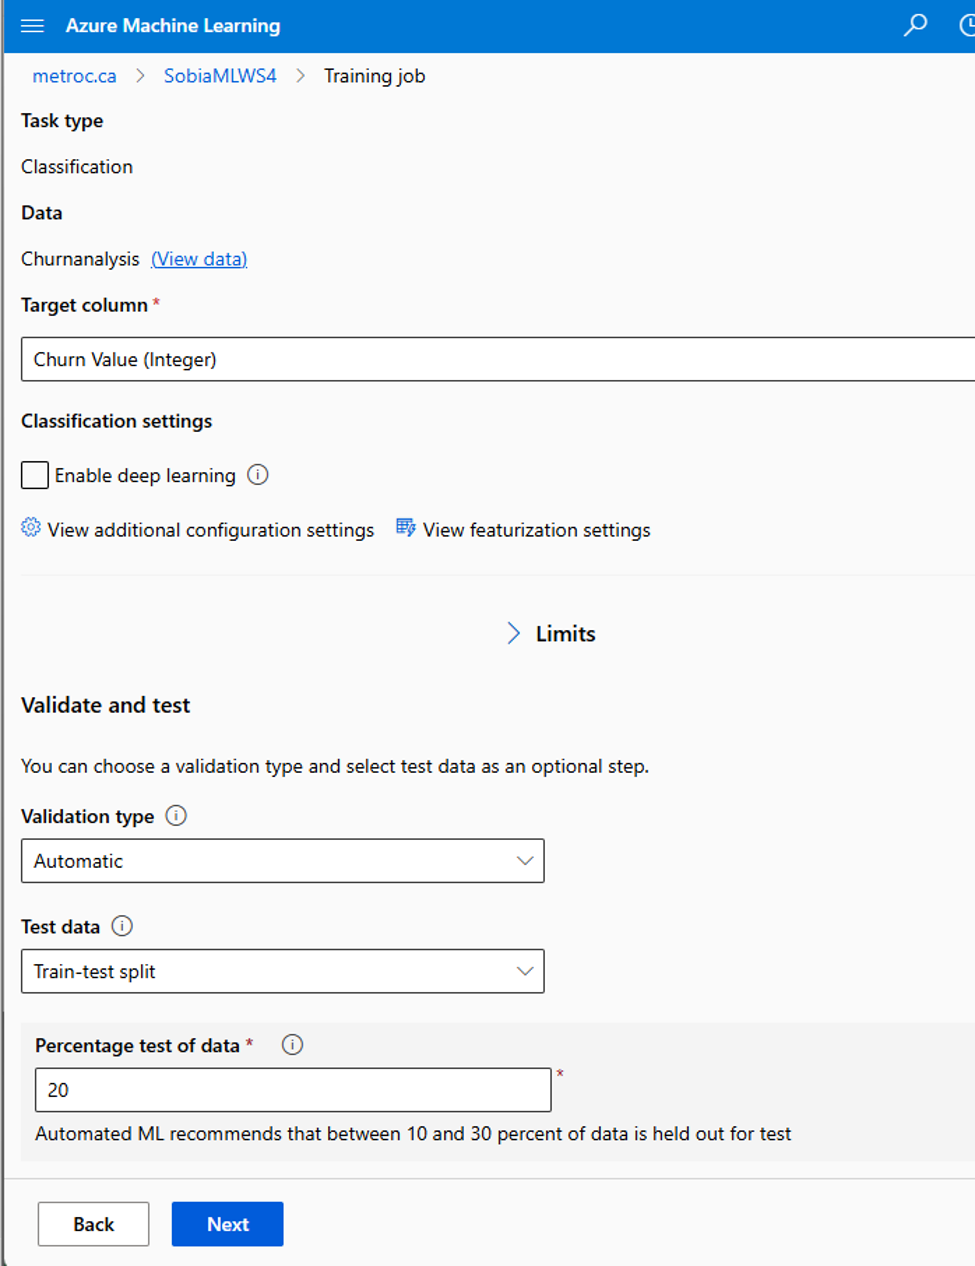

# Primary Metric Selection
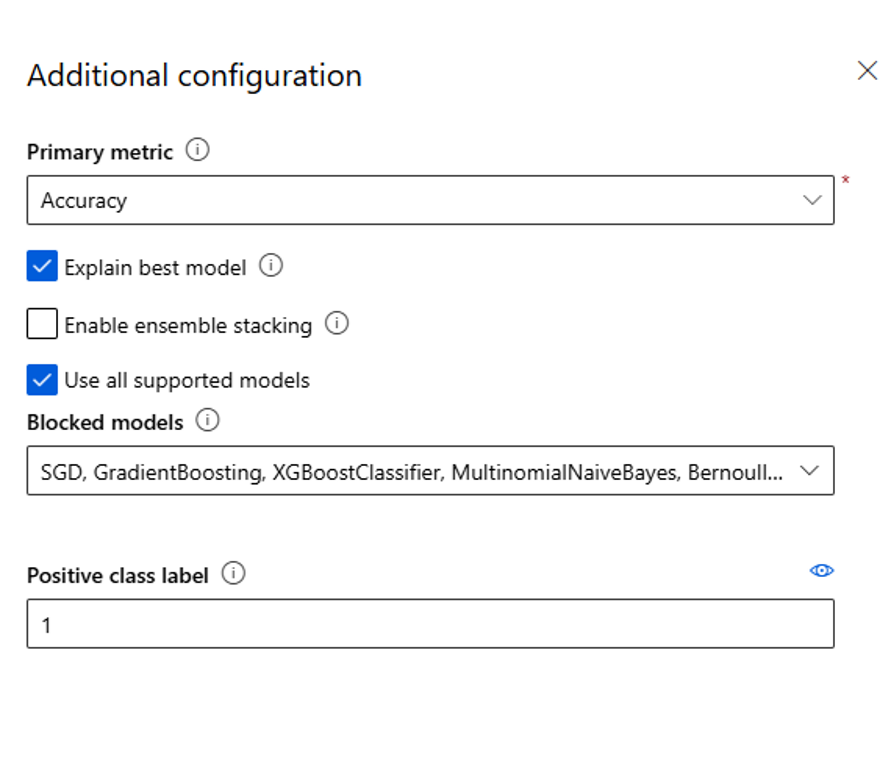

# Model training progress
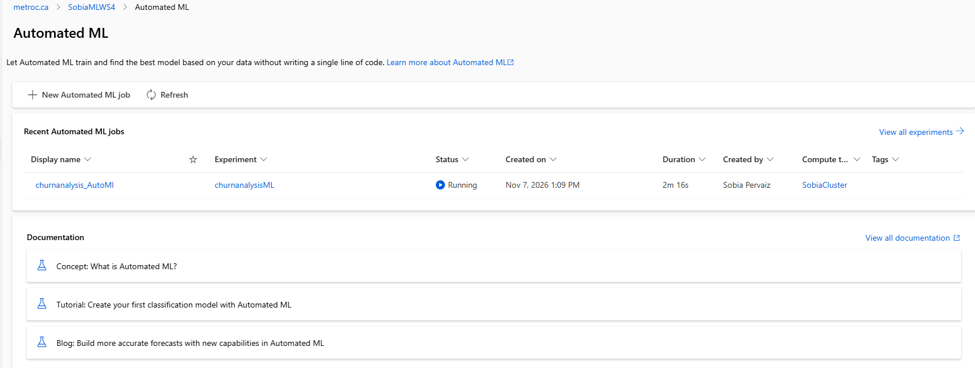

## AutoML Findings
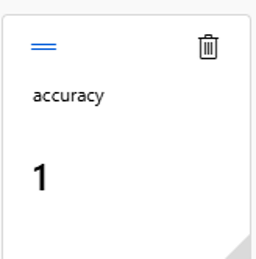
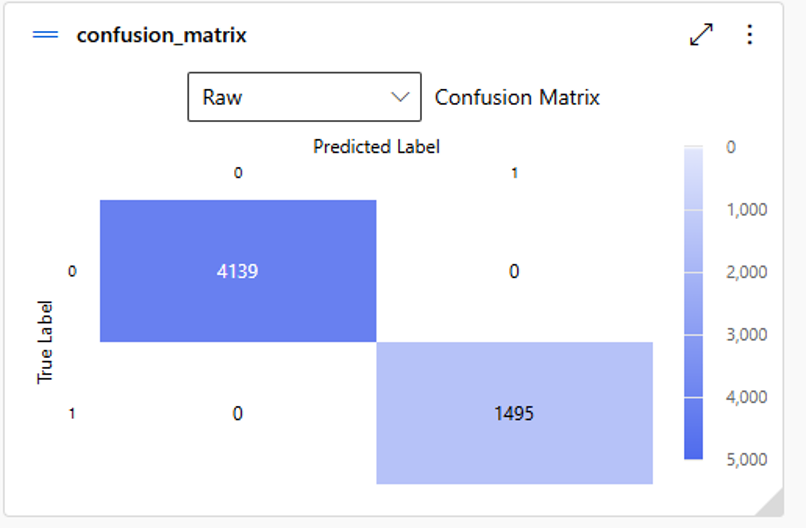
## Accuracy=1 is misleading for imbalanced data
- **True Negatives (0 predicted as 0): 4,139**

- **True Positives (1 predicted as 1): 1,495**

- **False Positives & False Negatives: Exactly 0**


## Conclusion & Recommendation
- Business Action: Connect the Azure ML live endpoint to  call-center agent’s screen

- Display customer’s Churn Probability score as a color-coded alert (Green, Yellow, Red)

 - If an agent sees a "Red" high-probability alert, they can be automatically authorized to offer retention incentives


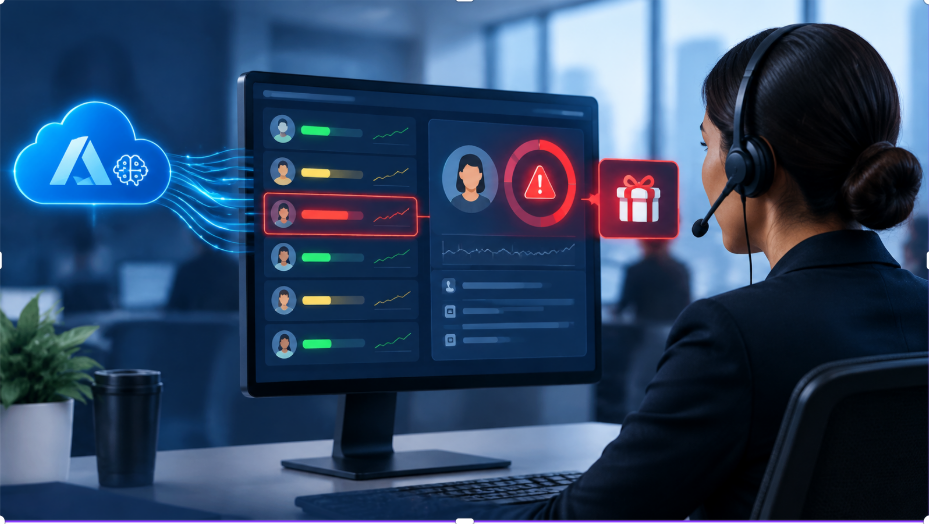